# The Weight Space of an Unchanged Quantized KV Cache
**Model:** Meta Llama 3.2 1B Instruct (attached as a Kaggle input)

This notebook gives an **explicit description** of the set of weights `W` for which the quantized KV cache of a prompt equals the baseline, and produces concrete points of that set.

## 1. The exact definition (from the lookup table)
With the frozen scales, level `q` covers `x in [(q-0.5)s, (q+0.5)s)`. So
`Region(P) = { W : L_i <= x_i(W) <= U_i  for every KV element i }`  (bounds saved per prompt).

## 2. The structure of that region (the key fact)
For a prompt of `T` tokens, every linear layer `m` (`q,k,v,o,gate,up,down`) only ever sees `T` input vectors `a_1..a_T` (rows of `A_m`, shape `T x in`). Let `Q_m` be an orthonormal basis of their span (`in x r`, `r <= T`).

> If a weight change satisfies `Delta_m @ Q_m = 0` for every layer, then `Delta_m @ a_t = 0` for every token: **no layer output changes, so every activation and the whole KV cache stay identical, for any size of Delta** (exactly, in exact arithmetic).

Also free: embedding rows of tokens that are not in the prompt, and all tensors that cannot influence any K/V (last-layer `q/o/MLP`, its `post_attention_layernorm`, the final norm). The RMSNorm weights of the reachable layers and the embedding rows of the prompt tokens are **not** free (they stay fixed in this description).

So the weight space splits into
* a **free subspace** `S_free` (dimension = almost everything: all but `out * T` dimensions per matrix): any change inside it keeps the cache, at any magnitude;
* a small **constrained part** (about `sum(out_m * r_m)` dimensions, `~1-2%` of all weights): changes here move the KV values and must stay inside the bounds.

`W in Region  <=  W = W0 + Delta_free + Delta_constrained`, where `Delta_free` is arbitrary in `S_free` and `Delta_constrained` is small enough that the KV values stay inside their intervals.

## 3. What the notebook does
| Step | What |
|---|---|
| A | Capture the inputs of every linear layer for the prompt, build the bases `Q_m`, count dimensions (free / constrained). |
| B | **Test the theory numerically**: random directions of size `eps` restricted to (i) the full space, (ii) the free subspace, (iii) the constrained subspace. Measure the change of the raw KV values and of the quantized cache. |
| C | **Construct points of the region**: `W0 + eps * ||W0|| * d_free`, followed by the solver from the previous notebook to remove float32 rounding noise; verified exactly by the real quantizer. |
| D | **Save the description** per prompt (`weight_space_<prompt>.pt`): token ids, scales, bounds, the bases `Q_m`, used token ids, dimension counts. Optionally save the constructed weights. |
| E | (optional) How far the *constrained* part can be pushed with compensation (the genuinely bounded directions). |

## Honest limitations
* The invariance is exact only in exact arithmetic. In float32, rounding of `W0 + Delta` acts like a perturbation of relative size ~1e-7 in the constrained directions; the solver removes the resulting few changed values.
* Everything is **per prompt** and in **float32** (not bf16).
* The description is a superset-free statement: points outside `S_free + small constrained part` can also lie in the region (nonlinear effects), so this is an inner description, not the exact boundary.
* RMSNorm weights and prompt-token embedding rows are treated as fixed (not free).

In [1]:
import os, glob, json, time, math, traceback, warnings, gc
from dataclasses import dataclass, field, asdict
from typing import List, Dict, Optional
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
print("torch", torch.__version__, "| transformers", transformers.__version__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(no GPU: this notebook needs ~13 GB of GPU memory)")

torch 2.11.0+cu130 | transformers 5.20.2
device: cuda Tesla T4


In [14]:
@dataclass
class Config:
    # ---- model / scope ----
    model_path: str = ""
    param_scope: str = "all"              # "all" | "kv_relevant"
    # ---- prompts ----
    use_chat_template: bool = True
    chat_template_date: str = "26 Jul 2024"
    max_prompt_tokens: int = 512
    dataset_files: Dict[str, str] = field(default_factory=dict)
    text_keys: tuple = ("prompt", "text", "question", "instruction", "input")
    max_prompts_per_dataset: Optional[int] = None
    # ---- quantization (identical to the earlier notebooks) ----
    qmax: int = 7
    # ---- solver (repair), as in the feasible-region notebook ----
    safety: float = 0.02
    repair_max_iters: int = 40
    repair_line_tries: int = 25
    # ---- subspace structure ----
    rank_tol: float = 1e-10               # singular values below rank_tol * largest are dropped from the basis
    # ---- experiments ----
    base_seed: int = 20240601
    n_dirs: int = 3
    val_curve_eps: tuple = (1e-6, 1e-4, 1e-2, 1e-1, 1.0)
    val_check_eps: float = 0.1
    curve_eps: tuple = (1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0)
    point_eps: tuple = (1e-3, 1e-2, 3e-1, 1.0)     # add 10.0 to probe far beyond ||W0|| (expected to fail)
    # ---- optional constrained-subspace walk (Step E) ----
    eps_start: float = 1e-6
    eps_max: float = 1.0
    growth: float = 1.5
    max_refine: int = 6
    rel_tol_follow: float = 0.05
    # ---- AutoPoison prompts (Stage 3) ----
    autopoison_path: str = ""             # autopoison_prompts.jsonl; empty -> auto-detect under /kaggle/input
    selected_path: str = ""               # autopoison_selected_10.jsonl; empty -> auto-detect under /kaggle/input
    max_ap_prompts: Optional[int] = None  # None = all 5,200
    n_verify_prompts: int = 12            # prompts (spread over the length range) that get the full verification
    gram_rank_tol: float = 1e-12          # fast structure: eigenvalue ratio of the Gram matrix (= singular-value ratio 1e-6)
    # ---- output ----
    save_description: bool = True         # ~65 MB per prompt
    save_weights: bool = False            # save constructed feasible weights (fp32, ~5 GB each)
    out_dir: str = "/kaggle/working/kv_weight_space"

cfg = Config()
os.makedirs(cfg.out_dir, exist_ok=True)

In [3]:
# [MODEL] locate + load the model (fp32, eager attention)
def find_model_dir():
    hits = []
    for f in glob.glob("/kaggle/input/**/config.json", recursive=True):
        try:
            c = json.load(open(f))
        except Exception:
            continue
        if c.get("model_type") == "llama" and c.get("num_hidden_layers") == 16 and c.get("hidden_size") == 2048:
            hits.append(os.path.dirname(f))
    return hits

if not cfg.model_path:
    hits = find_model_dir()
    print("Llama-3.2-1B-like model dirs found:", hits)
    assert hits, "Set cfg.model_path manually (folder with config.json + weights)."
    cfg.model_path = hits[0]
print("Using model:", cfg.model_path)

def load_model(path):
    tok = AutoTokenizer.from_pretrained(path)
    kw = dict(attn_implementation="eager", low_cpu_mem_usage=True)
    try:
        model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float32, **kw)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float32, **kw)
    return tok, model.to(DEVICE).eval()

tok, model = load_model(cfg.model_path)

Llama-3.2-1B-like model dirs found: ['/kaggle/input/models/makwingchi/llama-3.2-1b-instruct/transformers/default/1']
Using model: /kaggle/input/models/makwingchi/llama-3.2-1b-instruct/transformers/default/1


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

In [4]:
N_LAYERS = model.config.num_hidden_layers
assert next(model.parameters()).dtype == torch.float32

def in_scope(name, scope):
    if scope == "all":
        return True
    last = f"model.layers.{N_LAYERS-1}."
    if name == "model.norm.weight":
        return False
    if name.startswith(last) and not any(s in name for s in ("input_layernorm", "self_attn.k_proj", "self_attn.v_proj")):
        return False
    return True

PNAMES, PARAMS = [], []
for n, p in model.named_parameters():
    keep = in_scope(n, cfg.param_scope)
    p.requires_grad_(keep)
    if keep:
        PNAMES.append(n); PARAMS.append(p)
N_PARAMS = sum(p.numel() for p in PARAMS)
print(f"scope={cfg.param_scope}: {len(PARAMS)} tensors, {N_PARAMS/1e9:.3f}B parameters")

CHUNK = 1 << 24
def sq_norm(x):
    s = 0.0
    for c in x.flatten().split(CHUNK):
        s += float(torch.linalg.vector_norm(c.float(), dtype=torch.float64)) ** 2
    return s

def store_exact(p):
    """bf16 checkpoints are exactly bf16-representable in fp32: store as bf16 (half the memory, bit-exact restore)."""
    b = p.detach().to(torch.bfloat16)
    ok = all(torch.equal(bc.float(), pc) for bc, pc in zip(b.flatten().split(CHUNK), p.detach().flatten().split(CHUNK)))
    return (b, True) if ok else (p.detach().clone(), False)

with torch.no_grad():
    _pairs = [store_exact(p) for p in PARAMS]
    ORIG = [o for o, _ in _pairs]
    print(f"reference copy: {sum(f for _, f in _pairs)}/{len(ORIG)} tensors stored exactly as bf16")
    W_NORM = math.sqrt(sum(sq_norm(o) for o in ORIG))
print(f"||W||_2 = {W_NORM:.4f}")

@torch.no_grad()
def restore():
    for p, o in zip(PARAMS, ORIG):
        p.copy_(o)

@torch.no_grad()
def is_restored():
    return all(torch.equal(pc, oc.float()) for p, o in zip(PARAMS, ORIG)
               for pc, oc in zip(p.flatten().split(CHUNK), o.flatten().split(CHUNK)))

@torch.no_grad()
def rel_dist():
    """Actual ||W - W0||_2 / ||W0||_2 of the weights currently in the model."""
    ss = sum(sq_norm(pc - oc.float()) for p, o in zip(PARAMS, ORIG)
             for pc, oc in zip(p.flatten().split(CHUNK), o.flatten().split(CHUNK)))
    return math.sqrt(ss) / W_NORM

# CPU copy of the last feasible weights (needed to go back after a failed attempt)
SNAP = [torch.empty(p.shape, dtype=p.dtype, device="cpu") for p in PARAMS]
@torch.no_grad()
def take_snapshot():
    for s, p in zip(SNAP, PARAMS):
        s.copy_(p)
@torch.no_grad()
def load_snapshot():
    for s, p in zip(SNAP, PARAMS):
        p.copy_(s)

class Direction:
    """Reproducible global random direction: independent stream per tensor (SeedSequence.spawn), normalised globally."""
    def __init__(self):
        self._dn = {}
    def _seeds(self, seed):
        kids = np.random.SeedSequence(entropy=int(seed)).spawn(len(PARAMS))
        return [int(k.generate_state(1, dtype=np.uint64)[0] % (2**63 - 1)) for k in kids]
    def _raw(self, i, seeds):
        g = torch.Generator(device=PARAMS[i].device); g.manual_seed(seeds[i])
        return torch.randn(PARAMS[i].shape, generator=g, device=PARAMS[i].device, dtype=torch.float32)
    def norm(self, seed):
        if seed not in self._dn:
            seeds = self._seeds(seed)
            self._dn[seed] = math.sqrt(sum(sq_norm(self._raw(i, seeds)) for i in range(len(PARAMS))))
        return self._dn[seed]
    @torch.no_grad()
    def step(self, seed, dt):
        """weights += dt * ||W|| * d   (d: unit-norm direction)"""
        seeds = self._seeds(seed); coef = dt * W_NORM / self.norm(seed)
        for i, p in enumerate(PARAMS):
            p.add_(self._raw(i, seeds), alpha=coef)
DIRS = Direction()

scope=all: 146 tensors, 1.236B parameters
reference copy: 146/146 tensors stored exactly as bf16
||W||_2 = 706.9679


## Prompts, KV cache, baseline, lookup-table bounds, solver (unchanged from the previous notebook)

In [5]:
@dataclass
class PromptItem:
    pid: str
    dataset: str
    text: str

BUILTIN = {
    "general_qa": [
        "What is the capital of France, and what is it famous for?",
        "Explain the difference between weather and climate in two sentences.",
        "Who wrote 'Pride and Prejudice' and what is the book about?",
        "How does a refrigerator keep food cold?",
    ],
    "reasoning": [
        "If a train travels 60 km in 45 minutes, what is its average speed in km/h? Show your steps.",
        "Alice is taller than Bob, and Bob is taller than Carol. Who is the shortest?",
        "A farmer has 17 sheep and all but 9 run away. How many are left?",
        "What is the next number in the sequence 2, 6, 12, 20, 30?",
    ],
    "code": [
        "Write a Python function that returns the n-th Fibonacci number.",
        "Explain what a race condition is in concurrent programming.",
        "How do I reverse a linked list in C++?",
        "What does the SQL clause GROUP BY do?",
    ],
}

def load_dataset_file(path):
    ext = os.path.splitext(path)[1].lower()
    def pick(d):
        for k in cfg.text_keys:
            if k in d and isinstance(d[k], str):
                return d[k]
        raise KeyError(f"none of {cfg.text_keys} in {list(d)[:8]}")
    if ext == ".jsonl":
        return [pick(json.loads(l)) for l in open(path) if l.strip()]
    if ext == ".json":
        return [x if isinstance(x, str) else pick(x) for x in json.load(open(path))]
    if ext == ".csv":
        df = pd.read_csv(path); col = next(c for c in cfg.text_keys if c in df.columns)
        return df[col].astype(str).tolist()
    return [l.strip() for l in open(path) if l.strip()]

def build_prompts():
    sets = dict(BUILTIN)
    for name, path in cfg.dataset_files.items():
        sets[name] = load_dataset_file(path)
    items = []
    for name, texts in sets.items():
        if cfg.max_prompts_per_dataset:
            texts = texts[: cfg.max_prompts_per_dataset]
        items += [PromptItem(f"{name}-{i:04d}", name, t) for i, t in enumerate(texts)]
    return items

ALL_PROMPTS = build_prompts()
print(len(ALL_PROMPTS), "prompts")

def encode(text):
    if cfg.use_chat_template and tok.chat_template:
        s = tok.apply_chat_template([{"role": "user", "content": text}], tokenize=False,
                                    add_generation_prompt=True, date_string=cfg.chat_template_date)
        ids = tok(s, return_tensors="pt", add_special_tokens=False).input_ids
    else:
        ids = tok(text, return_tensors="pt").input_ids
    return ids[:, : cfg.max_prompt_tokens].to(DEVICE)

12 prompts


In [6]:
def _layer_kv(pkv, i):
    if hasattr(pkv, "layers"):
        l = pkv.layers[i]; return l.keys, l.values
    if hasattr(pkv, "key_cache"):
        return pkv.key_cache[i], pkv.value_cache[i]
    k, v = pkv[i]; return k, v

@torch.no_grad()
def extract_kv(input_ids):
    out = model.model(input_ids=input_ids, use_cache=True)
    return [tuple(t.detach().float().clone() for t in _layer_kv(out.past_key_values, i)) for i in range(N_LAYERS)]

def graph_kv(input_ids):
    with torch.enable_grad():
        out = model.model(input_ids=input_ids, use_cache=True)
        kv = [tuple(_layer_kv(out.past_key_values, i)) for i in range(N_LAYERS)]
    if not kv[0][0].requires_grad:
        raise RuntimeError("The KV cache is detached from the autograd graph in this transformers version.")
    return kv

def compute_scales(kv):
    sc = []
    for k, v in kv:
        pair = []
        for x in (k, v):
            s = x.abs().max() / cfg.qmax
            pair.append(torch.where(s > 0, s, torch.ones_like(s)))
        sc.append(tuple(pair))
    return sc

def quantize(kv, scales):
    return [tuple(torch.clamp(torch.round(x / s), -cfg.qmax, cfg.qmax).to(torch.int8) for x, s in ((k, sk), (v, sv)))
            for (k, v), (sk, sv) in zip(kv, scales)]

def compare_quant(q, q0):
    stats = torch.stack([torch.stack([(a != a0).sum(), (b != b0).sum()]) for (a, b), (a0, b0) in zip(q, q0)]).cpu().numpy()
    tot = int(sum(a.numel() + b.numel() for a, b in q0)); n = int(stats.sum())
    return dict(n_total=tot, n_changed=n, pct_changed=100.0 * n / tot, equal=(n == 0))

@dataclass
class Baseline:
    prompt: PromptItem
    ids: torch.Tensor
    raw: list
    scales: list
    q0: list
    n_total: int

def build_baseline(prompt):
    ids = encode(prompt.text)
    a, b = extract_kv(ids), extract_kv(ids)
    for (k1, v1), (k2, v2) in zip(a, b):
        if not (torch.equal(k1, k2) and torch.equal(v1, v2)):
            raise RuntimeError(f"{prompt.pid}: baseline forward pass is not bitwise deterministic")
    scales = compute_scales(a)
    q0 = quantize(a, scales)
    return Baseline(prompt, ids, a, scales, q0, sum(x.numel() + y.numel() for x, y in q0))

In [7]:
INF = float("inf")

def make_bounds(bl):
    """B[layer][0=K,1=V] = dict(lower, upper, lo_in, hi_in, s): per-element intervals in x-space."""
    B = []
    for li, (k, v) in enumerate(bl.raw):
        row = []
        for w, x in enumerate((k, v)):
            s = bl.scales[li][w]
            q0 = bl.q0[li][w].float()
            lower = torch.where(q0 <= -cfg.qmax, torch.full_like(x, -INF), (q0 - 0.5) * s)
            upper = torch.where(q0 >= cfg.qmax, torch.full_like(x, INF), (q0 + 0.5) * s)
            d_lo, d_up = (x - lower) / s, (upper - x) / s            # distances to the edges, in steps (>= 0, may be inf)
            sh_lo = torch.clamp(0.5 * d_lo, max=cfg.safety)          # never shrink past half the baseline distance
            sh_up = torch.clamp(0.5 * d_up, max=cfg.safety)
            row.append(dict(lower=lower, upper=upper, lo_in=lower + sh_lo * s, hi_in=upper - sh_up * s, s=s))
        B.append(row)
    return B

def out_of_bounds_mask(x, b):
    return (x < b["lower"]) | (x > b["upper"])

def lookup_table(bl, layer=0, which=0):
    """Printable lookup table of one K or V tensor, incl. how many fp16 numbers map to each level."""
    s = float(bl.scales[layer][which])
    f16 = np.arange(65536, dtype=np.uint16).view(np.float16).astype(np.float32)
    f16 = f16[np.isfinite(f16)]
    q16 = np.clip(np.round(f16 / s), -cfg.qmax, cfg.qmax).astype(int)
    n16 = np.bincount(q16 + cfg.qmax, minlength=2 * cfg.qmax + 1)
    q0 = bl.q0[layer][which].flatten().cpu().numpy().astype(int)
    ncache = np.bincount(q0 + cfg.qmax, minlength=2 * cfg.qmax + 1)
    rows = []
    for q in range(-cfg.qmax, cfg.qmax + 1):
        rows.append(dict(level=q, lower=-INF if q == -cfg.qmax else (q - 0.5) * s,
                         upper=INF if q == cfg.qmax else (q + 0.5) * s,
                         n_fp16_numbers=int(n16[q + cfg.qmax]), n_cache_elements=int(ncache[q + cfg.qmax])))
    return pd.DataFrame(rows), s

def hinge_loss(kv, B):
    """Sum of squared violations of the (tightened) bounds, in quantization-step units."""
    tot = 0.0
    for (k, v), row in zip(kv, B):
        for x, b in zip((k, v), row):
            tot = tot + (torch.relu(x - b["hi_in"]) / b["s"]).pow(2).sum() + (torch.relu(b["lo_in"] - x) / b["s"]).pow(2).sum()
    return tot

In [8]:
def check_equal(bl):
    q = quantize(extract_kv(bl.ids), bl.scales)
    return compare_quant(q, bl.q0)

def repair(bl, B, max_iters=None):
    """Move the CURRENT weights until every KV element is inside its interval (exact quantized equality)."""
    max_iters = cfg.repair_max_iters if max_iters is None else max_iters
    alpha, hist = None, []
    for it in range(max_iters + 1):
        kv_g = graph_kv(bl.ids)
        loss = hinge_loss(kv_g, B)
        eq = compare_quant(quantize([(k.detach(), v.detach()) for k, v in kv_g], bl.scales), bl.q0)
        lv = float(loss); hist.append((lv, eq["n_changed"]))
        if eq["equal"]:
            return dict(ok=True, iters=it, loss0=hist[0][0], n_changed0=hist[0][1], loss_end=lv, hist=hist)
        if it == max_iters or not math.isfinite(lv):
            break
        grads = torch.autograd.grad(loss, PARAMS, allow_unused=True)
        del kv_g, loss
        g2 = sum(sq_norm(g) for g in grads if g is not None)
        if not (g2 > 0 and math.isfinite(g2)):
            break
        a = alpha * 2 if alpha else lv / g2
        applied, improved = 0.0, False
        for _ in range(cfg.repair_line_tries):
            with torch.no_grad():
                d = a - applied
                for p, g in zip(PARAMS, grads):
                    if g is not None:
                        p.add_(g, alpha=-d)
                applied = a
                new = float(hinge_loss(extract_kv(bl.ids), B))
            if new < lv:
                improved = True; break
            a *= 0.5
        if not improved:
            with torch.no_grad():                         # undo the last failed trial
                for p, g in zip(PARAMS, grads):
                    if g is not None:
                        p.add_(g, alpha=applied)
            del grads
            break
        alpha = a
        del grads
    return dict(ok=False, iters=len(hist) - 1, loss0=hist[0][0], n_changed0=hist[0][1], loss_end=hist[-1][0], hist=hist)

def ensure_feasible(bl, B):
    eq = check_equal(bl)
    if eq["equal"]:
        return dict(ok=True, iters=0, loss0=0.0, n_changed0=0, loss_end=0.0)
    return repair(bl, B)

## Step A - the structure: inputs of every linear layer, bases `Q_m`, dimensions
`KINDS` classifies each parameter tensor: `linear` (constrained through its `Q_m`), `embed` (rows of prompt tokens constrained, others free), `gamma_fixed` (RMSNorm weights of reachable layers, kept fixed), `free_all` (cannot influence any K/V).

In [9]:
LINEARS = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")
MODULES = {n: m for n, m in model.named_modules() if n.startswith("model.layers.") and n.split(".")[-1] in LINEARS}

def param_kind(pname):
    if pname.endswith("embed_tokens.weight"):
        return ("embed", None)
    parts = pname.split(".")
    if parts[:2] == ["model", "layers"]:
        last = int(parts[2]) == N_LAYERS - 1
        if parts[-2] in LINEARS:
            if last and parts[-2] not in ("k_proj", "v_proj"):
                return ("free_all", None)               # last layer: q/o/MLP cannot influence any K/V
            return ("linear", ".".join(parts[:-1]))
        if parts[-2] == "input_layernorm":
            return ("gamma_fixed", None)
        if parts[-2] == "post_attention_layernorm":
            return ("free_all", None) if last else ("gamma_fixed", None)
    return ("free_all", None)                           # final norm, untied lm_head, ...

KINDS = {n: param_kind(n) for n in PNAMES}
print({k: sum(1 for v in KINDS.values() if v[0] == k) for k in ("linear", "embed", "gamma_fixed", "free_all")})

@torch.no_grad()
def build_structure(bl):
    inputs = {}
    hooks = [m.register_forward_hook(lambda mod, inp, out, n=n: inputs.__setitem__(n, inp[0].detach()[0].float()))
             for n, m in MODULES.items()]
    try:
        model.model(input_ids=bl.ids, use_cache=False)
    finally:
        for h in hooks:
            h.remove()
    bases, ranks, free = {}, {}, 0
    used = torch.unique(bl.ids).to(DEVICE)
    for n, p in zip(PNAMES, PARAMS):
        kind, mod = KINDS[n]
        if kind == "linear":
            A = inputs[mod].double()                                  # [T, in]: the T input vectors of this layer
            _, S, Vh = torch.linalg.svd(A, full_matrices=False)
            r = int((S > S[0] * cfg.rank_tol).sum())
            bases[n] = Vh[:r].T.contiguous().float()                  # orthonormal basis of their span, [in, r]
            ranks[n] = r
            free += p.shape[0] * (p.shape[1] - r)
        elif kind == "embed":
            free += (p.shape[0] - int(used.numel())) * p.shape[1]
        elif kind == "free_all":
            free += p.numel()
    del inputs
    return dict(pid=bl.prompt.pid, bases=bases, ranks=ranks, used=used, free_dims=int(free),
                constrained_dims=int(N_PARAMS - free), n_tokens=int(bl.ids.shape[1]))

def project(pname, Z, mode, S):
    """Project a raw Gaussian tensor Z (modified in place) onto the full / free / constrained part. None = zero."""
    if mode == "full":
        return Z
    kind, _ = KINDS[pname]
    if kind == "free_all":
        return Z if mode == "free" else None
    if kind == "gamma_fixed":
        return None if mode == "free" else Z
    if kind == "embed":
        mask = torch.zeros(Z.shape[0], dtype=torch.bool, device=Z.device); mask[S["used"]] = True
        Z[mask if mode == "free" else ~mask] = 0
        return Z
    Q = S["bases"][pname]
    Zc = (Z @ Q) @ Q.T                                                # component acting on the prompt's inputs
    if mode == "free":
        Z.sub_(Zc); return Z
    return Zc

STRUCT = None
class ModeDirection:
    """Reproducible random direction restricted to a part of the weight space; unit norm within that part."""
    def __init__(self):
        self._dn = {}
    def _seeds(self, seed):
        kids = np.random.SeedSequence(entropy=int(seed)).spawn(len(PARAMS))
        return [int(k.generate_state(1, dtype=np.uint64)[0] % (2**63 - 1)) for k in kids]
    def _raw(self, i, seeds):
        g = torch.Generator(device=PARAMS[i].device); g.manual_seed(seeds[i])
        return torch.randn(PARAMS[i].shape, generator=g, device=PARAMS[i].device, dtype=torch.float32)
    def norm(self, seed, mode):
        key = (int(seed), mode, STRUCT["pid"])
        if key not in self._dn:
            seeds, ss = self._seeds(seed), 0.0
            for i, n in enumerate(PNAMES):
                Z = project(n, self._raw(i, seeds), mode, STRUCT)
                if Z is not None:
                    ss += sq_norm(Z)
            self._dn[key] = math.sqrt(ss)
        return self._dn[key]
    @torch.no_grad()
    def step(self, seed, dt, mode="full"):
        """weights += dt * ||W|| * d_mode      (||d_mode|| = 1, so eps keeps the same meaning as before)"""
        seeds, coef = self._seeds(seed), dt * W_NORM / self.norm(seed, mode)
        for i, (n, p) in enumerate(zip(PNAMES, PARAMS)):
            Z = project(n, self._raw(i, seeds), mode, STRUCT)
            if Z is not None:
                p.add_(Z, alpha=coef)
DIRS = ModeDirection()

{'linear': 107, 'embed': 1, 'gamma_fixed': 31, 'free_all': 7}


## Steps B and C - test the theory, construct points of the region

In [10]:
def check_equal(bl):
    return compare_quant(quantize(extract_kv(bl.ids), bl.scales), bl.q0)

@torch.no_grad()
def eval_mode(bl, seed, mode, eps):
    """Change of the KV cache for a random direction of size eps restricted to `mode`."""
    try:
        restore(); DIRS.step(seed, eps, mode)
        kv = extract_kv(bl.ids)
    finally:
        restore()
    res = compare_quant(quantize(kv, bl.scales), bl.q0)
    dx = 0.0
    for l, (k, v) in enumerate(kv):
        for w, (x, x0) in enumerate(((k, bl.raw[l][0]), (v, bl.raw[l][1]))):
            dx = max(dx, float((x - x0).abs().max() / bl.scales[l][w]))
    res.update(mode=mode, eps=float(eps), max_dx_steps=dx)
    return res

def make_point(bl, B, seed, eps, mode="free"):
    """W = W0 + eps*||W0||*d_mode, then the solver removes float32 rounding noise. Leaves W in the model."""
    restore(); DIRS.step(seed, eps, mode)
    eq0 = check_equal(bl)
    r = dict(ok=True, iters=0) if eq0["equal"] else repair(bl, B)
    ok = bool(r["ok"] and check_equal(bl)["equal"])
    return dict(ok=ok, repair_iters=int(r["iters"]), n_changed_before_repair=int(eq0["n_changed"]),
                eps_nominal=float(eps), eps_actual=rel_dist())

def violations(bl, B):
    """Number of KV elements outside their lookup-table interval for the weights currently in the model."""
    kv = extract_kv(bl.ids)
    return int(sum(int(((x < b["lower"]) | (x > b["upper"])).sum()) for (k, v), row in zip(kv, B) for x, b in zip((k, v), row)))

## Step D - save the description of the weight space

In [11]:
def save_description(bl, B, S, path):
    payload = dict(
        prompt_id=bl.prompt.pid, text=bl.prompt.text, ids=bl.ids.cpu(), qmax=cfg.qmax,
        scales=[(a.cpu(), b.cpu()) for a, b in bl.scales], q0=[(a.cpu(), b.cpu()) for a, b in bl.q0],
        lower=[(r[0]["lower"].cpu(), r[1]["lower"].cpu()) for r in B],      # lookup-table bounds L_i
        upper=[(r[0]["upper"].cpu(), r[1]["upper"].cpu()) for r in B],      # lookup-table bounds U_i
        bases={n: q.cpu() for n, q in S["bases"].items()},                  # Q_m: Delta_m @ Q_m = 0  =>  free
        used_token_ids=S["used"].cpu(), kinds={n: k[0] for n, k in KINDS.items()},
        free_dims=S["free_dims"], constrained_dims=S["constrained_dims"], n_params=N_PARAMS, w_norm=W_NORM,
        how_to_use=("A weight change Delta is in the exact-invariance subspace iff: for every 'linear' tensor Delta @ Q == 0, "
                    "embedding rows of used_token_ids and all 'gamma_fixed' tensors are unchanged. "
                    "W is in the region iff lower <= KV(W) <= upper everywhere."))
    torch.save(payload, path)
    return os.path.getsize(path) / 2**20

## Stage 1 - validation (one prompt)

In [15]:
val_prompt = ALL_PROMPTS[0]
print("Validation prompt:", val_prompt.pid, "|", val_prompt.text)
bl = build_baseline(val_prompt); B = make_bounds(bl)
STRUCT = build_structure(bl)
T = STRUCT["n_tokens"]; ranks = np.array(list(STRUCT["ranks"].values()))
print(f"tokens T={T} | linear tensors constrained through a basis: {len(ranks)} (rank min/median/max = {ranks.min()}/{int(np.median(ranks))}/{ranks.max()})")
print(f"weights total        : {N_PARAMS:,}")
print(f"free subspace        : {STRUCT['free_dims']:,}  ({100*STRUCT['free_dims']/N_PARAMS:.2f}%)  -> any change here keeps the cache")
print(f"constrained dims     : {STRUCT['constrained_dims']:,}  ({100*STRUCT['constrained_dims']/N_PARAMS:.2f}%)  -> changes here are bounded")

checks, seed0 = {}, cfg.base_seed
err = max(float((Q.T @ Q - torch.eye(Q.shape[1], device=Q.device)).abs().max()) for Q in STRUCT["bases"].values())
checks["bases_orthonormal"] = err < 1e-4
checks["dims_add_up"] = (STRUCT["free_dims"] + STRUCT["constrained_dims"] == N_PARAMS)

rows = [eval_mode(bl, seed0, m, e) for m in ("full", "free", "constrained") for e in cfg.val_curve_eps]
cur = pd.DataFrame(rows)
print("\nChange of the KV cache for random directions of relative size eps (same seed):")
print("max_dx_steps = largest raw KV change in quantization-step units; changed = number of changed quantized values")
display(cur.pivot(index="eps", columns="mode", values="max_dx_steps").add_prefix("max_dx_steps/")
        .join(cur.pivot(index="eps", columns="mode", values="n_changed").add_prefix("changed/")))
g = lambda m, e, c: float(cur[(cur["mode"] == m) & (np.isclose(cur.eps, e))][c].iloc[0])
e_big = cfg.val_check_eps
checks["free_subspace_keeps_raw_KV"] = g("free", e_big, "max_dx_steps") < 1e-2 * max(g("full", e_big, "max_dx_steps"), 1e-12) + 1e-3
checks["free_subspace_keeps_quantized"] = g("free", 1e-2, "n_changed") <= 0.01 * max(g("full", 1e-2, "n_changed"), 1.0)

# Step C: a concrete point of the region far from W0
eps_pt = 0.1
pt = make_point(bl, B, seed0, eps_pt, "free")
print("\nconstructed point:", pt)
checks["constructed_point_is_feasible"] = bool(pt["ok"])
checks["constructed_point_exact_quantized_equality"] = check_equal(bl)["equal"]
checks["constructed_point_inside_bounds"] = (violations(bl, B) == 0)
checks["constructed_point_far_from_W0"] = pt["eps_actual"] > 0.5 * eps_pt
restore()
checks["restored_exactly"] = is_restored()

print()
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
WS_VALIDATION_PASSED = all(checks.values())
print("\nVALIDATION PASSED" if WS_VALIDATION_PASSED else "\nVALIDATION FAILED - read the checks above")

Validation prompt: general_qa-0000 | What is the capital of France, and what is it famous for?
tokens T=49 | linear tensors constrained through a basis: 107 (rank min/median/max = 35/49/49)
weights total        : 1,235,814,400
free subspace        : 1,218,361,344  (98.59%)  -> any change here keeps the cache
constrained dims     : 17,453,056  (1.41%)  -> changes here are bounded

Change of the KV cache for random directions of relative size eps (same seed):
max_dx_steps = largest raw KV change in quantization-step units; changed = number of changed quantized values


mode,max_dx_steps/constrained,max_dx_steps/free,max_dx_steps/full,changed/constrained,changed/free,changed/full
eps,,,,,,
0.000001,0.000510,0.000029,0.000092,23,1,2
0.000100,0.052681,0.000067,0.006238,1816,1,214
0.010000,4.212923,0.000061,0.635825,169108,0,21281
0.100000,9.243508,0.000106,4.227776,450353,1,202861
1.000000,16.586964,7.720514,12.240815,564777,100830,536735



constructed point: {'ok': True, 'repair_iters': 1, 'n_changed_before_repair': 1, 'eps_nominal': 0.1, 'eps_actual': 0.10000000365375193}

PASS bases_orthonormal
PASS dims_add_up
PASS free_subspace_keeps_raw_KV
PASS free_subspace_keeps_quantized
PASS constructed_point_is_feasible
PASS constructed_point_exact_quantized_equality
PASS constructed_point_inside_bounds
PASS constructed_point_far_from_W0
PASS restored_exactly

VALIDATION PASSED


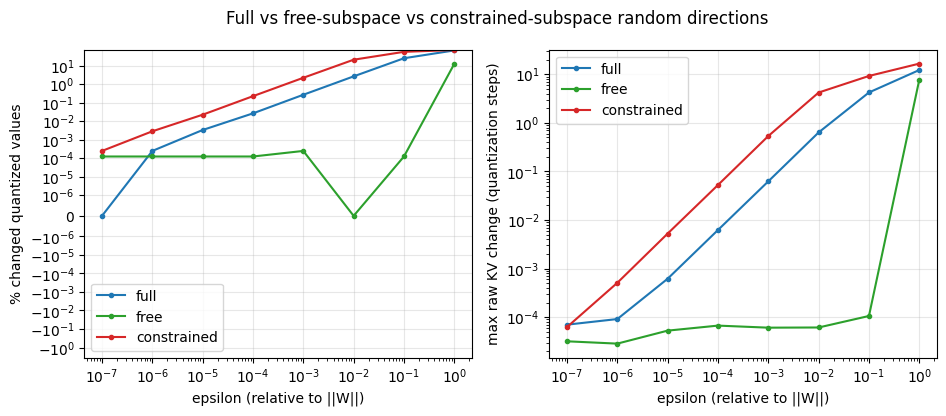

In [16]:
# Visual: change of the quantized cache vs eps for the three kinds of direction
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
eps_grid = cfg.curve_eps
curv = pd.DataFrame([eval_mode(bl, seed0, m, e) for m in ("full", "free", "constrained") for e in eps_grid])
for m, c in zip(("full", "free", "constrained"), ("C0", "C2", "C3")):
    g_ = curv[curv["mode"] == m]
    axs[0].plot(g_.eps, g_.pct_changed, marker="o", ms=3, label=m, color=c)
    axs[1].plot(g_.eps, g_.max_dx_steps, marker="o", ms=3, label=m, color=c)
axs[0].set_xscale("log"); axs[0].set_yscale("symlog", linthresh=1e-6); axs[0].set_ylabel("% changed quantized values")
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].set_ylabel("max raw KV change (quantization steps)")
for a in axs:
    a.set_xlabel("epsilon (relative to ||W||)"); a.grid(alpha=.3); a.legend()
fig.suptitle("Full vs free-subspace vs constrained-subspace random directions")
plt.savefig(f"{cfg.out_dir}/ws_fig_modes_validation.png", dpi=150, bbox_inches="tight"); plt.show()

### Step E (optional) - how far can the *constrained* part be pushed?
Walk away from `W0` along a random direction **inside the constrained subspace only**; the solver compensates whenever the cache would change. The distance reached is the extent of the genuinely bounded directions (the free subspace has no limit). Takes a few minutes per direction.

In [17]:
def follow_direction(bl, B, seed, mode="constrained"):
    t0 = time.time()
    restore(); take_snapshot()
    t_acc, eps_act, t_fail, t_target = 0.0, 0.0, None, cfg.eps_start
    refine, n_rep, steps, status = 0, 0, [], "limit_found"
    while True:
        load_snapshot()
        DIRS.step(seed, t_target - t_acc, mode)
        r = ensure_feasible(bl, B)
        steps.append(dict(t_nominal=t_target, ok=bool(r["ok"]), repair_iters=r["iters"], eps_actual=rel_dist()))
        if r["ok"]:
            n_rep += int(r["iters"] > 0); take_snapshot(); t_acc = t_target; eps_act = steps[-1]["eps_actual"]
            if t_acc >= cfg.eps_max * (1 - 1e-9):
                status = "reached_eps_max"; break
            if t_fail is None:
                t_target = min(t_acc * cfg.growth, cfg.eps_max)
            else:
                if (t_fail - t_acc) / t_acc <= cfg.rel_tol_follow:
                    break
                t_target = math.sqrt(t_acc * t_fail)
        else:
            t_fail = t_target; refine += 1
            if refine > cfg.max_refine:
                break
            t_target = math.sqrt(t_acc * t_fail) if t_acc > 0 else t_fail / 2
    load_snapshot()
    return dict(mode=mode, seed=int(seed), status=status, eps_nominal_feasible=t_acc, eps_actual_feasible=eps_act,
                eps_first_failure=t_fail if t_fail else np.nan, n_steps=len(steps), n_steps_repaired=n_rep,
                seconds=time.time() - t0)

RUN_WALK = False        # set True to run Step E for the validation prompt
if RUN_WALK:
    for mode in ("constrained", "full"):
        rec = follow_direction(bl, B, seed0, mode)
        print(rec); assert check_equal(bl)["equal"]; restore()

In [18]:
# Save the description of the weight space of the validation prompt
if cfg.save_description:
    mb = save_description(bl, B, STRUCT, os.path.join(cfg.out_dir, f"weight_space_{val_prompt.pid}.pt"))
    print(f"saved weight_space_{val_prompt.pid}.pt ({mb:.0f} MB)")
del bl, B
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

saved weight_space_general_qa-0000.pt (65 MB)


## Stage 2 - all prompts
For every prompt: structure (dimensions), curves for the three kinds of direction, constructed points of the region at several distances (`cfg.point_eps`), and the saved description. Resumable.

In [19]:
RUN_ALL = True          # set True after validation passed

def jsonl_append(path, rows):
    with open(path, "a") as f:
        for r in rows:
            f.write(json.dumps(r, default=float) + "\n")

def jsonl_read(path):
    return pd.read_json(path, lines=True) if os.path.exists(path) else pd.DataFrame()

SPATH = os.path.join(cfg.out_dir, "ws_structure.jsonl")
CPATH = os.path.join(cfg.out_dir, "ws_curves.jsonl")
PPATH = os.path.join(cfg.out_dir, "ws_points.jsonl")

def write_run_config():
    json.dump(dict(config=asdict(cfg), w_norm=W_NORM, n_params=N_PARAMS, torch=torch.__version__,
                   transformers=transformers.__version__, gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"),
              open(os.path.join(cfg.out_dir, "ws_config.json"), "w"), indent=2, default=str)

def run_full_analysis(prompt, seeds, tag=""):
    # structure + curves for full/free/constrained directions + constructed points + saved description
    global STRUCT
    t0 = time.time()
    bl = build_baseline(prompt); B = make_bounds(bl); STRUCT = build_structure(bl)
    try:
        jsonl_append(CPATH, [dict(prompt_id=prompt.pid, seed=cfg.base_seed, **eval_mode(bl, cfg.base_seed, m, e))
                             for m in ("full", "free", "constrained") for e in cfg.curve_eps])
        pts = []
        for seed in seeds:
            for e in cfg.point_eps:
                r = make_point(bl, B, seed, e, "free"); restore()
                pts.append(dict(prompt_id=prompt.pid, dataset=prompt.dataset, seed=int(seed), **r))
                print(f"  [{prompt.pid}] seed={seed} eps={e:g}: ok={r['ok']} repair_iters={r['repair_iters']} "
                      f"(changed before repair: {r['n_changed_before_repair']}) actual distance={r['eps_actual']:.3e}")
        jsonl_append(PPATH, pts)
        if cfg.save_description:
            save_description(bl, B, STRUCT, os.path.join(cfg.out_dir, f"weight_space_{prompt.pid}.pt"))
        rk = np.array(list(STRUCT["ranks"].values()))
        jsonl_append(SPATH, [dict(prompt_id=prompt.pid, dataset=prompt.dataset, n_tokens=STRUCT["n_tokens"], n_params=N_PARAMS,
                                  free_dims=STRUCT["free_dims"], constrained_dims=STRUCT["constrained_dims"],
                                  free_fraction=STRUCT["free_dims"] / N_PARAMS, rank_min=int(rk.min()), rank_max=int(rk.max()),
                                  seconds=time.time() - t0)])          # written last: marks the prompt as finished
        print(f"{tag}{prompt.pid}: free {100*STRUCT['free_dims']/N_PARAMS:.2f}% of the weights, {time.time()-t0:.0f}s")
    except Exception:
        traceback.print_exc(); restore()
    finally:
        STRUCT = None
        del bl, B
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

if RUN_ALL:
    assert WS_VALIDATION_PASSED, "Validation did not pass."
    write_run_config()
    done = set(jsonl_read(SPATH).prompt_id) if os.path.exists(SPATH) else set()
    seeds = [cfg.base_seed + i for i in range(cfg.n_dirs)]
    for pi, prompt in enumerate(ALL_PROMPTS):
        if prompt.pid not in done:
            run_full_analysis(prompt, seeds, tag=f"[{pi+1}/{len(ALL_PROMPTS)}] ")
    print("saved to", cfg.out_dir)

  [general_qa-0000] seed=20240601 eps=0.001: ok=True repair_iters=1 (changed before repair: 2) actual distance=1.000e-03
  [general_qa-0000] seed=20240601 eps=0.01: ok=True repair_iters=0 (changed before repair: 0) actual distance=1.000e-02
  [general_qa-0000] seed=20240601 eps=0.3: ok=False repair_iters=2 (changed before repair: 4) actual distance=3.000e-01
  [general_qa-0000] seed=20240601 eps=1: ok=False repair_iters=11 (changed before repair: 100830) actual distance=1.000e+00
  [general_qa-0000] seed=20240602 eps=0.001: ok=True repair_iters=1 (changed before repair: 1) actual distance=1.000e-03
  [general_qa-0000] seed=20240602 eps=0.01: ok=True repair_iters=1 (changed before repair: 1) actual distance=1.000e-02
  [general_qa-0000] seed=20240602 eps=0.3: ok=False repair_iters=1 (changed before repair: 2) actual distance=3.000e-01
  [general_qa-0000] seed=20240602 eps=1: ok=False repair_iters=7 (changed before repair: 95830) actual distance=1.000e+00
  [general_qa-0000] seed=2024060

## Stage 3 - AutoPoison prompts (5,200 Alpaca-style instructions)
Source: `poison_data_release` of AutoPoison. Both released files (McDonald's injection and over-refusal) contain **the same 5,200 prompts** (`instruction` + optional `input`); they differ only in the *responses*. The weight space of a prompt depends only on the prompt tokens, so one set of 5,200 prompts covers both files. (The responses are not part of the prompt cache.)

Full verification (curves, constructed points, saved description) takes minutes per prompt, so for 5,200 prompts it is split in two:
1. **Structure pass for all prompts (fast)**: one forward pass per prompt, the rank of every linear layer's input matrix, and the dimension of the free / constrained parts. Gives the free fraction of the weight space for every prompt.
2. **Full verification for a sample** (`cfg.n_verify_prompts`, spread over the length range): the complete Stage 2 analysis and the saved description.

Upload `autopoison_prompts.jsonl` (provided with this notebook, 1.2 MB) as a Kaggle dataset, or set `cfg.autopoison_path`.

In [23]:
def find_ap_file():
    if cfg.autopoison_path:
        return cfg.autopoison_path
    hits = glob.glob("/kaggle/input/**/autopoison_prompts.jsonl", recursive=True)
    return hits[0] if hits else ""

AP_FILE = find_ap_file()
print("AutoPoison prompts file:", AP_FILE or "NOT FOUND (upload autopoison_prompts.jsonl as a Kaggle dataset or set cfg.autopoison_path)")

def load_autopoison():
    rows = [json.loads(l) for l in open(AP_FILE) if l.strip()]
    if cfg.max_ap_prompts:
        rows = rows[: cfg.max_ap_prompts]
    return [PromptItem(f"ap-{r['sample_id']}", "autopoison", r["text"]) for r in rows]

@torch.no_grad()
def fast_structure(prompt):
    # dimensions of the free / constrained parts without bases or KV baseline (rank via the Gram matrix of the inputs)
    ids = encode(prompt.text)
    inputs = {}
    hooks = [m.register_forward_hook(lambda mod, inp, out, n=n: inputs.__setitem__(n, inp[0].detach()[0]))
             for n, m in MODULES.items()]
    try:
        model.model(input_ids=ids, use_cache=False)
    finally:
        for h in hooks:
            h.remove()
    used = int(torch.unique(ids).numel()); free, ranks, cache = 0, [], {}
    for n, p in zip(PNAMES, PARAMS):
        kind, mod = KINDS[n]
        if kind == "linear":
            if mod not in cache:
                A = inputs[mod].double()
                ev = torch.linalg.eigvalsh(A @ A.T)
                cache[mod] = int((ev > ev[-1] * cfg.gram_rank_tol).sum())
            r = cache[mod]; ranks.append(r); free += p.shape[0] * (p.shape[1] - r)
        elif kind == "embed":
            free += (p.shape[0] - used) * p.shape[1]
        elif kind == "free_all":
            free += p.numel()
    rk = np.array(ranks)
    return dict(prompt_id=prompt.pid, dataset=prompt.dataset, n_tokens=int(ids.shape[1]), n_params=N_PARAMS,
                free_dims=int(free), constrained_dims=int(N_PARAMS - free), free_fraction=free / N_PARAMS,
                rank_min=int(rk.min()), rank_max=int(rk.max()), rank_mean=float(rk.mean()))

APATH = os.path.join(cfg.out_dir, "autopoison_structure.jsonl")
RUN_AUTOPOISON = False       # set True after validation passed
RUN_AP_VERIFY = True         # include the full verification of a sample (Stage 3b)

if RUN_AUTOPOISON:
    assert WS_VALIDATION_PASSED, "Validation did not pass."
    assert AP_FILE, "autopoison_prompts.jsonl not found"
    AP_PROMPTS = load_autopoison()
    print(len(AP_PROMPTS), "AutoPoison prompts")
    # consistency check (INFO): the fast rank should agree with the SVD-based structure of Stage 1
    p0 = AP_PROMPTS[0]; fs = fast_structure(p0)
    _bl = build_baseline(p0); _S = build_structure(_bl)
    print(f"fast vs SVD structure for {p0.pid}: free dims {fs['free_dims']:,} vs {_S['free_dims']:,}")
    del _bl, _S
    done = set(jsonl_read(APATH).prompt_id) if os.path.exists(APATH) else set()
    t0 = time.time(); batch = []
    for i, p in enumerate(AP_PROMPTS):
        if p.pid not in done:
            batch.append(fast_structure(p))
        if batch and (len(batch) >= 50 or i == len(AP_PROMPTS) - 1):
            jsonl_append(APATH, batch); batch = []
            print(f"[{i+1}/{len(AP_PROMPTS)}] {time.time()-t0:.0f}s elapsed")
    print("structure pass done")

AutoPoison prompts file: /kaggle/input/datasets/erfansalima/quantized-weight-space/autopoison_selected_10.jsonl
10 AutoPoison prompts
fast vs SVD structure for ap-11813: free dims 1,217,653,760 vs 1,217,653,760
[10/10] 3s elapsed
structure pass done


In [24]:
# Stage 3b: full verification for a sample spread over the prompt-length range
if RUN_AUTOPOISON and RUN_AP_VERIFY:
    A_ = jsonl_read(APATH).sort_values("n_tokens").reset_index(drop=True)
    pick = sorted(set(np.linspace(0, len(A_) - 1, min(cfg.n_verify_prompts, len(A_))).round().astype(int)))
    sample_ids = list(A_.loc[pick, "prompt_id"])
    print("verifying", len(sample_ids), "prompts, token counts:", list(A_.loc[pick, "n_tokens"]))
    by_id = {p.pid: p for p in AP_PROMPTS}
    write_run_config()
    done = set(jsonl_read(SPATH).prompt_id) if os.path.exists(SPATH) else set()
    seeds = [cfg.base_seed + i for i in range(cfg.n_dirs)]
    for i, pid in enumerate(sample_ids):
        if pid not in done:
            run_full_analysis(by_id[pid], seeds, tag=f"[AP {i+1}/{len(sample_ids)}] ")

verifying 10 prompts, token counts: [43, 43, 45, 45, 49, 51, 53, 56, 57, 68]
  [ap-8744] seed=20240601 eps=0.001: ok=True repair_iters=2 (changed before repair: 1) actual distance=1.000e-03
  [ap-8744] seed=20240601 eps=0.01: ok=True repair_iters=3 (changed before repair: 2) actual distance=1.000e-02
  [ap-8744] seed=20240601 eps=0.3: ok=True repair_iters=1 (changed before repair: 1) actual distance=3.000e-01
  [ap-8744] seed=20240601 eps=1: ok=False repair_iters=14 (changed before repair: 82228) actual distance=1.000e+00
  [ap-8744] seed=20240602 eps=0.001: ok=True repair_iters=4 (changed before repair: 1) actual distance=1.000e-03
  [ap-8744] seed=20240602 eps=0.01: ok=True repair_iters=4 (changed before repair: 2) actual distance=1.000e-02
  [ap-8744] seed=20240602 eps=0.3: ok=True repair_iters=4 (changed before repair: 2) actual distance=3.000e-01
  [ap-8744] seed=20240602 eps=1: ok=False repair_iters=6 (changed before repair: 85970) actual distance=1.000e+00
  [ap-8744] seed=20240

KeyboardInterrupt: 

In [ ]:
AP = jsonl_read(APATH)
if len(AP):
    AP.to_csv(os.path.join(cfg.out_dir, "autopoison_structure.csv"), index=False)
    print(f"{len(AP)} AutoPoison prompts analysed")
    display(AP[["n_tokens", "free_fraction", "constrained_dims", "rank_min", "rank_max"]].describe().T)
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
    axs[0].hist(AP.n_tokens, bins=40); axs[0].set_xlabel("prompt tokens T"); axs[0].set_ylabel("# prompts")
    axs[1].hist(100 * AP.free_fraction, bins=40, color="C2"); axs[1].set_xlabel("free part of the weight space (%)")
    axs[2].scatter(AP.n_tokens, 100 * AP.constrained_dims / AP.n_params, s=3, alpha=.4, color="C3")
    axs[2].set_xlabel("prompt tokens T"); axs[2].set_ylabel("constrained part (% of weights)")
    for a in axs: a.grid(alpha=.3)
    plt.savefig(f"{cfg.out_dir}/autopoison_structure.png", dpi=150, bbox_inches="tight"); plt.show()

## Stage 4 - the selected AutoPoison prompts (5 from each file)
`autopoison_selected_10.jsonl`: 5 prompts drawn at random (fixed seed) from the McDonald's-injection file and 5 different prompts from the over-refusal file. Upload it as a Kaggle dataset (or set `cfg.selected_path`). For each of the 10 prompts the notebook runs the complete analysis of Stage 2: dimensions of the free / constrained parts, curves for full / free / constrained directions, constructed points of the weight space at several distances, and the saved description `weight_space_<pid>.pt`.

Note: both files contain the same prompts and differ only in the responses, which are not part of the prompt cache, so the file a prompt comes from does not change its weight space.

In [26]:
SEL_FILE = cfg.selected_path or next(iter(glob.glob("/kaggle/input/**/autopoison_selected_10.jsonl", recursive=True)), "")
print("selected prompts file:", SEL_FILE or "NOT FOUND (upload autopoison_selected_10.jsonl as a Kaggle dataset or set cfg.selected_path)")
RUN_SELECTED = True        # set True after validation passed

if RUN_SELECTED:
    assert WS_VALIDATION_PASSED, "Validation did not pass."
    assert SEL_FILE, "autopoison_selected_10.jsonl not found"
    SEL = [json.loads(l) for l in open(SEL_FILE) if l.strip()]
    SEL_PROMPTS = [PromptItem(r["pid"], r["dataset"], r["text"]) for r in SEL]
    print(len(SEL_PROMPTS), "prompts:", [p.pid for p in SEL_PROMPTS])
    write_run_config()
    done = set(jsonl_read(SPATH).prompt_id) if os.path.exists(SPATH) else set()
    seeds = [cfg.base_seed + i for i in range(cfg.n_dirs)]
    for i, p in enumerate(SEL_PROMPTS):
        if p.pid not in done:
            run_full_analysis(p, seeds, tag=f"[selected {i+1}/{len(SEL_PROMPTS)}] ")

selected prompts file: /kaggle/input/datasets/erfansalima/quantized-weight-space/autopoison_selected_10.jsonl
10 prompts: ['mcd-11813', 'mcd-8744', 'mcd-24509', 'mcd-10492', 'mcd-29510', 'refusal-51436', 'refusal-1363', 'refusal-23064', 'refusal-47377', 'refusal-40622']
  [mcd-11813] seed=20240601 eps=0.001: ok=True repair_iters=0 (changed before repair: 0) actual distance=1.000e-03
  [mcd-11813] seed=20240601 eps=0.01: ok=True repair_iters=0 (changed before repair: 0) actual distance=1.000e-02
  [mcd-11813] seed=20240601 eps=0.3: ok=True repair_iters=1 (changed before repair: 1) actual distance=3.000e-01
  [mcd-11813] seed=20240601 eps=1: ok=False repair_iters=19 (changed before repair: 91755) actual distance=1.000e+00
  [mcd-11813] seed=20240602 eps=0.001: ok=True repair_iters=0 (changed before repair: 0) actual distance=1.000e-03
  [mcd-11813] seed=20240602 eps=0.01: ok=True repair_iters=0 (changed before repair: 0) actual distance=1.000e-02
  [mcd-11813] seed=20240602 eps=0.3: ok=T

## Analysis

,prompt_id,n_tokens,free_dims,constrained_dims,free_fraction,rank_min,rank_max
0,general_qa-0000,49,1218361344,17453056,0.985877,35,49
1,general_qa-0001,47,1219068928,16745472,0.986450,34,47
2,general_qa-0002,52,1217292288,18522112,0.985012,38,52
3,general_qa-0003,43,1220494336,15320064,0.987603,30,43
4,reasoning-0000,60,1214456832,21357568,0.982718,43,60
5,reasoning-0001,53,1216956416,18857984,0.984740,35,53
6,reasoning-0002,54,1216584704,19229696,0.984440,39,54
7,reasoning-0003,58,1215195136,20619264,0.983315,36,58
8,code-0000,47,1219068928,16745472,0.986450,34,47
9,code-0001,46,1219425280,16389120,0.986738,33,46


,prompt_id,eps_nominal,n,n_ok,repair_iters_max,changed_before_repair_max,eps_actual_median
0,ap-24509,0.001,3,3,1,1,0.001
1,ap-24509,0.010,3,3,1,1,0.010
2,ap-24509,0.300,3,3,2,1,0.300
3,ap-24509,1.000,3,0,13,88283,1.000
4,ap-8744,0.001,3,3,4,1,0.001
...,...,...,...,...,...,...,...
91,refusal-47377,1.000,3,0,9,117909,1.000
92,refusal-51436,0.001,3,0,3,3,0.001
93,refusal-51436,0.010,3,1,3,2,0.010
94,refusal-51436,0.300,3,2,6,5,0.300


constructed points verified feasible: 155 / 288


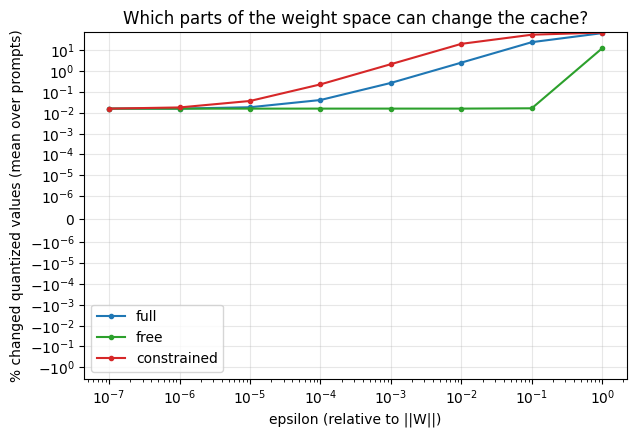

In [27]:
ST, CU, PT = jsonl_read(SPATH), jsonl_read(CPATH), jsonl_read(PPATH)
if len(ST):
    display(ST[["prompt_id", "n_tokens", "free_dims", "constrained_dims", "free_fraction", "rank_min", "rank_max"]])
    ST.to_csv(os.path.join(cfg.out_dir, "ws_structure.csv"), index=False)
if len(PT):
    pt_sum = (PT.groupby(["prompt_id", "eps_nominal"]).agg(n=("ok", "count"), n_ok=("ok", "sum"),
              repair_iters_max=("repair_iters", "max"), changed_before_repair_max=("n_changed_before_repair", "max"),
              eps_actual_median=("eps_actual", "median")).reset_index())
    pt_sum.to_csv(os.path.join(cfg.out_dir, "ws_points_summary.csv"), index=False)
    display(pt_sum)
    print("constructed points verified feasible:", int(PT.ok.sum()), "/", len(PT))
if len(CU):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for m, c in zip(("full", "free", "constrained"), ("C0", "C2", "C3")):
        g_ = CU[CU["mode"] == m].groupby("eps").pct_changed.mean()
        ax.plot(g_.index, g_.values, marker="o", ms=3, label=m, color=c)
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1e-6); ax.set_xlabel("epsilon (relative to ||W||)")
    ax.set_ylabel("% changed quantized values (mean over prompts)"); ax.grid(alpha=.3); ax.legend()
    ax.set_title("Which parts of the weight space can change the cache?")
    plt.savefig(f"{cfg.out_dir}/ws_fig_modes.png", dpi=150, bbox_inches="tight"); plt.show()

### How to read the results
* **`free_fraction`**: share of all weights in the exact-invariance subspace (the cache is unchanged for *any* change of those weights). `constrained_dims` is what is left: the only dimensions that can move the cache.
* **Curves**: the *free* curve should stay at (or very near) zero up to eps = 1 and beyond, the *constrained* curve should rise first, and the *full* random direction lies in between (it has a small component in the constrained part). Any non-zero free-curve value at large eps is float32 rounding noise, not a real effect.
* **`ws_points`**: concrete weights `W0 + eps*||W0||*d_free (+ tiny solver correction)` verified by the real quantizer, at distances up to 10x the norm of the weights. `changed_before_repair` shows how much rounding noise the solver had to remove.
* **`weight_space_<prompt>.pt`**: the explicit description (bounds + bases) of that prompt's weight space.